## SCRAPING DATA

In [ ]:
!pip install google-play-scraper
from datetime import date
from google_play_scraper import reviews, Sort
import pandas as pd

# Contoh: aplikasi JAKI di Indonesia
result, _ = reviews(
    'id.go.jakarta.smartcity.jaki',          # app ID dari URL Play Store
    lang='id',
    country='id',
    sort=Sort.NEWEST,
    count=10000
)
data = [{
    'id': r['reviewId'],
    'teks': r['content'],
    'rating': r['score'],        # <-- tambahan: rating 1-5
    'tanggal': r['at'],
    'sumber': 'playstore'
} for r in result]

df = pd.DataFrame(data)
df.to_csv('scraped_Jaki.csv', index=False)
print('Total review:', len(df))
print('Rentang Tanggal:', df['tanggal'].min(), 'sampai', df['tanggal'].max())
print('Distribusi Rating:')
print(df['rating'].value_counts().sort_index())
df.head()

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.2/50.2 kB 1.6 MB/s eta 0:00:00
Total review: 4934
Rentang Tanggal: 2019-09-27 13:14:50 sampai 2026-09-07 18:19:00
Distribusi Rating:
rating
1    1717
2     326
3     307
4     314
5    2270
Name: count, dtype: int64


,id,teks,rating,tanggal,sumber
0,95bb5b2d-ba28-4e7c-a217-77e01c3dc716,kalo kelamaan miara aplikasi ini.. bisa2 hp yg...,1,2026-09-07 18:19:00,playstore
1,605ebe2d-de4e-49a3-a247-054925714f2a,apk ga bisa jaga data si pelapor hal hasil pel...,1,2026-09-04 15:01:02,playstore
2,16201016-a29b-4ffc-b825-249671bd350d,kunfayakun,5,2026-09-04 14:54:53,playstore
3,3743eba2-8c78-4e0b-8479-84ebb7d32563,masi proses verifikasi,5,2026-08-23 09:53:35,playstore
4,36f6fb58-0bee-44a9-92c2-cfe78d202396,percuma ini aplikasi gue mau komplain tentang ...,1,2026-08-20 02:13:25,playstore


In [ ]:
# Sesuaikan path/nama file dengan lokasi Anda
df = pd.read_csv('scraped_Jaki.csv')

In [ ]:
df.head ()
print("Shape data :", df.shape)
display(df.head())

Shape data : (4934, 5)


,id,teks,rating,tanggal,sumber
0,95bb5b2d-ba28-4e7c-a217-77e01c3dc716,kalo kelamaan miara aplikasi ini.. bisa2 hp yg...,1,2026-09-07 18:19:00,playstore
1,605ebe2d-de4e-49a3-a247-054925714f2a,apk ga bisa jaga data si pelapor hal hasil pel...,1,2026-09-04 15:01:02,playstore
2,16201016-a29b-4ffc-b825-249671bd350d,kunfayakun,5,2026-09-04 14:54:53,playstore
3,3743eba2-8c78-4e0b-8479-84ebb7d32563,masi proses verifikasi,5,2026-08-23 09:53:35,playstore
4,36f6fb58-0bee-44a9-92c2-cfe78d202396,percuma ini aplikasi gue mau komplain tentang ...,1,2026-08-20 02:13:25,playstore


### Exploratory Data Analysis (EDA)

In [ ]:
# INFORMASI DATA
# ============================================================

print("=== INFO DATA ===")
df.info()

print("\n=== UKURAN DATA ===")
print(df.shape)

print("\n=== 5 DATA TERATAS ===")
display(df.head())

print("\n=== STATISTIK NUMERIK ===")
display(df.describe().T)

=== INFO DATA ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4934 entries, 0 to 4933
Data columns (total 5 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   id       4934 non-null   object
 1   teks     4934 non-null   object
 2   rating   4934 non-null   int64 
 3   tanggal  4934 non-null   object
 4   sumber   4934 non-null   object
dtypes: int64(1), object(4)
memory usage: 192.9+ KB

=== UKURAN DATA ===
(4934, 5)

=== 5 DATA TERATAS ===


,id,teks,rating,tanggal,sumber
0,95bb5b2d-ba28-4e7c-a217-77e01c3dc716,kalo kelamaan miara aplikasi ini.. bisa2 hp yg...,1,2026-09-07 18:19:00,playstore
1,605ebe2d-de4e-49a3-a247-054925714f2a,apk ga bisa jaga data si pelapor hal hasil pel...,1,2026-09-04 15:01:02,playstore
2,16201016-a29b-4ffc-b825-249671bd350d,kunfayakun,5,2026-09-04 14:54:53,playstore
3,3743eba2-8c78-4e0b-8479-84ebb7d32563,masi proses verifikasi,5,2026-08-23 09:53:35,playstore
4,36f6fb58-0bee-44a9-92c2-cfe78d202396,percuma ini aplikasi gue mau komplain tentang ...,1,2026-08-20 02:13:25,playstore



=== STATISTIK NUMERIK ===


,count,mean,std,min,25%,50%,75%,max
rating,4934.0,3.221727,1.820299,1.0,1.0,4.0,5.0,5.0


In [ ]:
# Menampilkan semua baris yang saling duplikat satu sama lain
semua_kembaran = df[df.duplicated(subset=['id'], keep=False)]

# Disarankan untuk diurutkan berdasarkan kolom 'id' agar mudah dianalisa
semua_kembaran = semua_kembaran.sort_values(by='id')
print(semua_kembaran)

Empty DataFrame
Columns: [id, teks, rating, tanggal, sumber]
Index: []


## PREPROCESSING

In [ ]:
import re

def clean_text_bert(text):
    if not isinstance(text, str): return ''

    text = text.lower()                                     # 1. Huruf kecil
    text = re.sub(r'https?://\S+|www\.\S+', '', text)       # 2. Hapus URL
    text = re.sub(r'@\w+|#\w+', '', text)                   # 3. Hapus mention/hashtag
    text = re.sub(r'(.)\1{2,}', r'\1\1', text)               # 5. Normalisasi huruf berulang
    text = re.sub(r'\s+', ' ', text).strip()                 # 6. Rapikan spasi

    return text

df['teks_clean'] = df['teks'].apply(clean_text_bert)
print(df[['teks', 'teks_clean']].head())

                                                teks  \
0  kalo kelamaan miara aplikasi ini.. bisa2 hp yg...   
1  apk ga bisa jaga data si pelapor hal hasil pel...   
2                                         kunfayakun   
3                             masi proses verifikasi   
4  percuma ini aplikasi gue mau komplain tentang ...   

                                          teks_clean  
0  kalo kelamaan miara aplikasi ini.. bisa2 hp yg...  
1  apk ga bisa jaga data si pelapor hal hasil pel...  
2                                         kunfayakun  
3                             masi proses verifikasi  
4  percuma ini aplikasi gue mau komplain tentang ...  


In [ ]:
# Menghapus kolom yang tidak diperlukan
df = df.drop(columns=['id', 'tanggal', 'sumber'])

# Menampilkan hasilnya
df.head()

,teks,rating,teks_clean
0,kalo kelamaan miara aplikasi ini.. bisa2 hp yg...,1,kalo kelamaan miara aplikasi ini.. bisa2 hp yg...
1,apk ga bisa jaga data si pelapor hal hasil pel...,1,apk ga bisa jaga data si pelapor hal hasil pel...
2,kunfayakun,5,kunfayakun
3,masi proses verifikasi,5,masi proses verifikasi
4,percuma ini aplikasi gue mau komplain tentang ...,1,percuma ini aplikasi gue mau komplain tentang ...


### NORMALISASI

In [ ]:
# Kamus normalisasi
norm_dict = {
    "yg": "yang", "ga": "tidak", "gak": "tidak", "aja": "saja",
    "udah": "sudah", "banget": "sekali", "ok": "oke",
    "dki": "daerah khusus ibukota", "kalo": "kalau", "gk": "tidak",
    "apk": "aplikasi", "sy": "saya", "udh": "sudah", "tp": "tapi",
    "tdk": "tidak", "app": "aplikasi", "min": "admin", "pake": "pakai",
    "mulu": "selalu", "klo": "kalau", "utk": "untuk", "sdh": "sudah",
    "dah": "sudah", "eror": "error", "ko": "kok", "bgt": "sekali",
    "g": "tidak", "gw": "saya", "biar": "agar", "bs": "bisa",
    "tau": "tahu", "knp": "kenapa", "tgl": "tanggal", "blm": "belum",
    "ngisi": "mengisi", "doang": "saja", "bener": "benar", "ngga": "tidak",
    "sampe": "sampai", "karna": "karena", "gabisa": "tidak bisa",
    "dgn": "dengan", "sya": "saya", "trus": "terus", "kaya": "seperti",
    "sklrga": "keluarga","baguss": "bagus"
}

# Definisikan fungsi normalize_text
def normalize_text(text):
    text = str(text).lower()
    for word, replacement in norm_dict.items():
        text = re.sub(rf'\b{word}\b', replacement, text)
    return text

# Terapkan fungsi yang sudah didefinisikan ke dalam kolom 'teks_clean'
df['teks_clean'] = df['teks_clean'].apply(normalize_text)

# Tampilkan hasilnya (opsional: tampilkan kedua kolom untuk melihat perubahannya)
print(df[['teks', 'teks_clean']].head())

                                                teks  \
0  kalo kelamaan miara aplikasi ini.. bisa2 hp yg...   
1  apk ga bisa jaga data si pelapor hal hasil pel...   
2                                         kunfayakun   
3                             masi proses verifikasi   
4  percuma ini aplikasi gue mau komplain tentang ...   

                                          teks_clean  
0  kalau kelamaan miara aplikasi ini.. bisa2 hp y...  
1  aplikasi tidak bisa jaga data si pelapor hal h...  
2                                         kunfayakun  
3                             masi proses verifikasi  
4  percuma ini aplikasi gue mau komplain tentang ...  


In [ ]:
df.head ()

,teks,rating,teks_clean
0,kalo kelamaan miara aplikasi ini.. bisa2 hp yg...,1,kalau kelamaan miara aplikasi ini.. bisa2 hp y...
1,apk ga bisa jaga data si pelapor hal hasil pel...,1,aplikasi tidak bisa jaga data si pelapor hal h...
2,kunfayakun,5,kunfayakun
3,masi proses verifikasi,5,masi proses verifikasi
4,percuma ini aplikasi gue mau komplain tentang ...,1,percuma ini aplikasi gue mau komplain tentang ...


## LABELING

In [ ]:
!pip install transformers torch
from transformers import pipeline

sentiment_analyzer = pipeline(
    "sentiment-analysis",
    model="w11wo/indonesian-roberta-base-sentiment-classifier"
)

hasil = sentiment_analyzer("Aplikasinya bagus sekali, sangat memuaskan!")
print(hasil)

config.json:   0%|          | 0.00/929 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  499MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/328 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/808k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/467k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.38M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

[{'label': 'positive', 'score': 0.9924820065498352}]


In [ ]:
from transformers import pipeline
import pandas as pd

#  Inisialisasi Model IndoBERT
sentiment_analyzer = pipeline(
    "sentiment-analysis",
    model="w11wo/indonesian-roberta-base-sentiment-classifier",
    truncation=True,
    max_length=512,
    top_k=None # top_k=None penting agar output mengeluarkan skor untuk ketiga label
)

# Proses Prediksi (Pastikan nama kolom sesuai)
texts = df['teks_clean'].tolist()

batch_size = 32
all_scores = []
for i in range(0, len(texts), batch_size):
    batch = texts[i:i+batch_size]
    all_scores.extend(sentiment_analyzer(batch))

#  Fungsi Resolve Label (Versi Lebih Singkat)
def resolve_label(scores):
    # Ekstrak hasil skor ke dalam dictionary
    score_dict = {s['label'].lower(): s['score'] for s in scores}

    # Langsung bandingkan skor 'positive' dan 'negative'.
    # Data yang sejatinya 'neutral' otomatis dipaksa masuk ke kubu
    # yang probabilitasnya (meski kecil) lebih dominan.
    if score_dict['positive'] >= score_dict['negative']:
        return 'positif'
    else:
        return 'negatif'

# 4. Terapkan ke DataFrame
df['label'] = [resolve_label(s) for s in all_scores]

# Tampilkan jumlah masing-masing label
print(df['label'].value_counts())

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

label
negatif    3166
positif    1768
Name: count, dtype: int64


In [ ]:
df.head ()

,teks,rating,teks_clean,label
0,kalo kelamaan miara aplikasi ini.. bisa2 hp yg...,1,kalau kelamaan miara aplikasi ini.. bisa2 hp y...,negatif
1,apk ga bisa jaga data si pelapor hal hasil pel...,1,aplikasi tidak bisa jaga data si pelapor hal h...,negatif
2,kunfayakun,5,kunfayakun,negatif
3,masi proses verifikasi,5,masi proses verifikasi,negatif
4,percuma ini aplikasi gue mau komplain tentang ...,1,percuma ini aplikasi gue mau komplain tentang ...,negatif


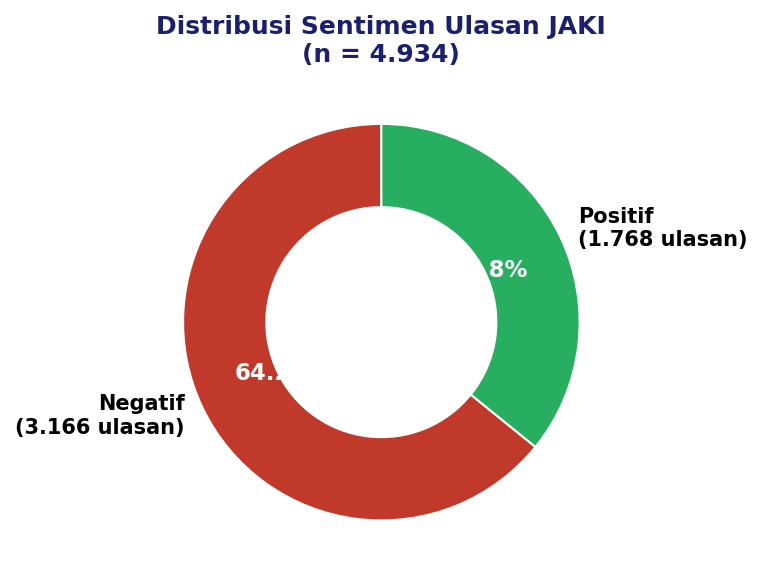

In [ ]:
import matplotlib.pyplot as plt
import matplotlib

matplotlib.rcParams['font.family'] = 'DejaVu Sans'

# Warna tema
navy = '#1a1f6e'
red = '#c0392b'
green = '#27ae60'

# Hitung otomatis dari kolom label (tidak hardcode)
counts = df['label'].value_counts()
total = counts.sum()

labels = [f"{idx.capitalize()}\n({val:,} ulasan)".replace(',', '.')
          for idx, val in counts.items()]
sizes = counts.values
colors = [red if idx == 'negatif' else green for idx in counts.index]

fig, ax = plt.subplots(figsize=(5, 4), dpi=150)
wedges, texts, autotexts = ax.pie(
    sizes,
    labels=labels,
    colors=colors,
    autopct='%1.1f%%',
    startangle=90,
    wedgeprops=dict(width=0.42, edgecolor='white'),
    textprops={'fontsize': 10, 'fontweight': 'bold'}
)

for at in autotexts:
    at.set_color('white')
    at.set_fontsize(11)

ax.set_title(f'Distribusi Sentimen Ulasan JAKI\n(n = {total:,})'.replace(',', '.'),
             fontsize=12, fontweight='bold', color=navy)

plt.tight_layout()
plt.savefig('distribusi_sentimen.png', transparent=True, dpi=150)
plt.show()

In [ ]:
# Labeling berdasarkan rating: 1-3 = negatif, 4-5 = positif
df['label_rating'] = df['rating'].apply(lambda x: 'negatif' if x <= 3 else 'positif')

# Tampilkan distribusi label
print(df['label_rating'].value_counts())

label_rating
positif    2584
negatif    2350
Name: count, dtype: int64


In [ ]:
df.head ()

,teks,rating,teks_clean,label,label_rating
0,kalo kelamaan miara aplikasi ini.. bisa2 hp yg...,1,kalau kelamaan miara aplikasi ini.. bisa2 hp y...,negatif,negatif
1,apk ga bisa jaga data si pelapor hal hasil pel...,1,aplikasi tidak bisa jaga data si pelapor hal h...,negatif,negatif
2,kunfayakun,5,kunfayakun,negatif,positif
3,masi proses verifikasi,5,masi proses verifikasi,negatif,positif
4,percuma ini aplikasi gue mau komplain tentang ...,1,percuma ini aplikasi gue mau komplain tentang ...,negatif,negatif


In [ ]:
### PERBANDINGAN LABEL RATING vs LABEL INDOBERT

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report
import matplotlib.pyplot as plt

# Cross-tab: lihat sebaran label_rating vs label IndoBERT
print("=== Cross-tabulation: Label Rating vs Label IndoBERT ===")
crosstab = pd.crosstab(df['label_rating'], df['label'],
                        rownames=['Label Rating'], colnames=['Label IndoBERT'])
print(crosstab)

=== Cross-tabulation: Label Rating vs Label IndoBERT ===
Label IndoBERT  negatif  positif
Label Rating                    
negatif            2244      106
positif             922     1662


In [ ]:
# Hitung tingkat kesepakatan (agreement rate)
agreement = (df['label_rating'] == df['label']).mean()
print(f"\nTingkat kesepakatan (agreement rate): {agreement:.2%}")


Tingkat kesepakatan (agreement rate): 79.16%


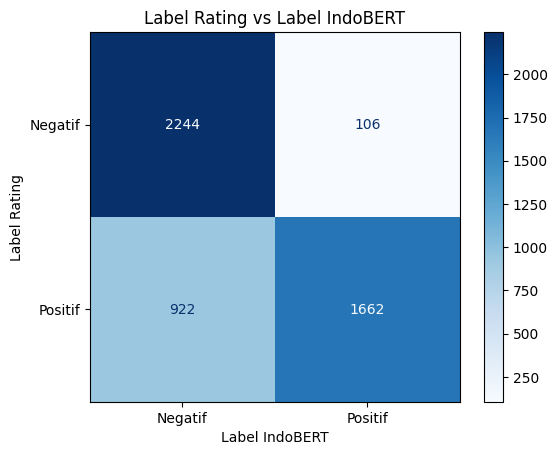

In [ ]:
# Confusion matrix (label_rating sebagai acuan, label IndoBERT sebagai pembanding)
cm = confusion_matrix(df['label_rating'], df['label'], labels=['negatif', 'positif'])
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Negatif', 'Positif'])
disp.plot(cmap='Blues')
plt.title('Label Rating vs Label IndoBERT')
plt.xlabel('Label IndoBERT')
plt.ylabel('Label Rating')
plt.show()

In [ ]:
# Classification report
print("\n=== Classification Report (Label Rating sebagai acuan) ===")
print(classification_report(df['label_rating'], df['label']))



=== Classification Report (Label Rating sebagai acuan) ===
              precision    recall  f1-score   support

     negatif       0.71      0.95      0.81      2350
     positif       0.94      0.64      0.76      2584

    accuracy                           0.79      4934
   macro avg       0.82      0.80      0.79      4934
weighted avg       0.83      0.79      0.79      4934



In [ ]:
# Tampilkan contoh kasus yang TIDAK sepakat
tidak_sepakat = df[df['label_rating'] != df['label']][['teks', 'rating', 'label_rating', 'label']]
print(f"\nJumlah kasus tidak sepakat: {len(tidak_sepakat)} dari {len(df)} ({len(tidak_sepakat)/len(df):.2%})")
display(tidak_sepakat.head(20))


Jumlah kasus tidak sepakat: 1028 dari 4934 (20.84%)


,teks,rating,label_rating,label
2,kunfayakun,5,positif,negatif
3,masi proses verifikasi,5,positif,negatif
20,sudah normal kembali,5,positif,negatif
29,aplikasinya bagus dan cepat juga respon mungki...,5,positif,negatif
36,kapan selesainya mau cek pajak masih dalam per...,4,positif,negatif
42,Fitur Antrean Faskes loading mulu,1,negatif,positif
53,"Aplikasi nya bagus , fast respon namun sistem ...",2,negatif,positif
56,ini sangat membantu cuma dari saya lihat dan a...,4,positif,negatif
69,bintang menentukan kualitas,1,negatif,positif
78,tolong dong di perbaiki lagi masa harus login ...,4,positif,negatif


In [ ]:
# Simpan untuk pengecekan manual
tidak_sepakat.to_csv('kasus_tidak_sepakat.csv', index=False)
print("Kasus tidak sepakat disimpan ke 'kasus_tidak_sepakat.csv'")

Kasus tidak sepakat disimpan ke 'kasus_tidak_sepakat.csv'


In [ ]:
# Diagnostik: cek skor mentah (positive/neutral/negative) untuk teks-teks pendek yang "salah label"
sample_texts = ['ok', 'oke', 'mantap', 'top banget', 'puas', '👍', 'bagus']

diag = sentiment_analyzer(sample_texts)

for teks, scores in zip(sample_texts, diag):
    score_dict = {s['label'].lower(): round(s['score'], 4) for s in scores}
    print(f"'{teks}': {score_dict}")

'ok': {'negative': 0.993, 'neutral': 0.0049, 'positive': 0.0021}
'oke': {'negative': 0.9073, 'neutral': 0.0562, 'positive': 0.0365}
'mantap': {'positive': 0.9755, 'negative': 0.0201, 'neutral': 0.0043}
'top banget': {'positive': 0.6785, 'negative': 0.2848, 'neutral': 0.0368}
'puas': {'negative': 0.5249, 'positive': 0.4493, 'neutral': 0.0258}
'👍': {'negative': 0.5378, 'positive': 0.3184, 'neutral': 0.1438}
'bagus': {'positive': 0.7057, 'negative': 0.2763, 'neutral': 0.0179}


In [ ]:
### FINALISASI LABEL

# Gunakan label_rating sebagai label final untuk modeling
# (label IndoBERT tetap disimpan sebagai label_indobert untuk bahan diskusi limitasi)
df['label_indobert'] = df['label']       # simpan hasil IndoBERT untuk referensi/laporan
df['label'] = df['label_rating']         # label_rating jadi label final

print("Distribusi label final (dari rating):")
print(df['label'].value_counts())

Distribusi label final (dari rating):
label
positif    2584
negatif    2350
Name: count, dtype: int64


### Tokenizing

In [ ]:
import nltk
nltk.download('punkt')
nltk.download('punkt_tab')
from nltk.tokenize import word_tokenize

df['tokenizing'] = df['teks_clean'].apply(word_tokenize)
df.head()

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.


,teks,rating,teks_clean,label,label_rating,label_indobert,tokenizing
0,kalo kelamaan miara aplikasi ini.. bisa2 hp yg...,1,kalau kelamaan miara aplikasi ini.. bisa2 hp y...,negatif,negatif,negatif,"[kalau, kelamaan, miara, aplikasi, ini, .., bi..."
1,apk ga bisa jaga data si pelapor hal hasil pel...,1,aplikasi tidak bisa jaga data si pelapor hal h...,negatif,negatif,negatif,"[aplikasi, tidak, bisa, jaga, data, si, pelapo..."
2,kunfayakun,5,kunfayakun,positif,positif,negatif,[kunfayakun]
3,masi proses verifikasi,5,masi proses verifikasi,positif,positif,negatif,"[masi, proses, verifikasi]"
4,percuma ini aplikasi gue mau komplain tentang ...,1,percuma ini aplikasi gue mau komplain tentang ...,negatif,negatif,negatif,"[percuma, ini, aplikasi, gue, mau, komplain, t..."


In [ ]:
!pip install Sastrawi
from Sastrawi.StopWordRemover.StopWordRemoverFactory import StopWordRemoverFactory

stopword_factory = StopWordRemoverFactory()
stopwords = set(stopword_factory.get_stop_words())  # ambil daftar kata, bukan objek remover

df['teks_stopword'] = df['tokenizing'].apply(lambda tokens: [t for t in tokens if t not in stopwords])
df.head()

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 209.7/209.7 kB 3.4 MB/s eta 0:00:00


,teks,rating,teks_clean,label,label_rating,label_indobert,tokenizing,teks_stopword
0,kalo kelamaan miara aplikasi ini.. bisa2 hp yg...,1,kalau kelamaan miara aplikasi ini.. bisa2 hp y...,negatif,negatif,negatif,"[kalau, kelamaan, miara, aplikasi, ini, .., bi...","[kalau, kelamaan, miara, aplikasi, .., bisa2, ..."
1,apk ga bisa jaga data si pelapor hal hasil pel...,1,aplikasi tidak bisa jaga data si pelapor hal h...,negatif,negatif,negatif,"[aplikasi, tidak, bisa, jaga, data, si, pelapo...","[aplikasi, jaga, data, si, pelapor, hasil, pel..."
2,kunfayakun,5,kunfayakun,positif,positif,negatif,[kunfayakun],[kunfayakun]
3,masi proses verifikasi,5,masi proses verifikasi,positif,positif,negatif,"[masi, proses, verifikasi]","[masi, proses, verifikasi]"
4,percuma ini aplikasi gue mau komplain tentang ...,1,percuma ini aplikasi gue mau komplain tentang ...,negatif,negatif,negatif,"[percuma, ini, aplikasi, gue, mau, komplain, t...","[percuma, aplikasi, gue, mau, komplain, pelaya..."


In [ ]:
from Sastrawi.Stemmer.StemmerFactory import StemmerFactory

stemmer_factory = StemmerFactory()
stemmer = stemmer_factory.create_stemmer()

df['teks_stemmed'] = df['teks_stopword'].apply(lambda tokens: stemmer.stem(' '.join(tokens)))
df.head()

,teks,rating,teks_clean,label,label_rating,label_indobert,tokenizing,teks_stopword,teks_stemmed
0,kalo kelamaan miara aplikasi ini.. bisa2 hp yg...,1,kalau kelamaan miara aplikasi ini.. bisa2 hp y...,negatif,negatif,negatif,"[kalau, kelamaan, miara, aplikasi, ini, .., bi...","[kalau, kelamaan, miara, aplikasi, .., bisa2, ...",kalau lama miara aplikasi bisa2 hp jadi korban...
1,apk ga bisa jaga data si pelapor hal hasil pel...,1,aplikasi tidak bisa jaga data si pelapor hal h...,negatif,negatif,negatif,"[aplikasi, tidak, bisa, jaga, data, si, pelapo...","[aplikasi, jaga, data, si, pelapor, hasil, pel...",aplikasi jaga data si lapor hasil lapor jadi s...
2,kunfayakun,5,kunfayakun,positif,positif,negatif,[kunfayakun],[kunfayakun],kunfayakun
3,masi proses verifikasi,5,masi proses verifikasi,positif,positif,negatif,"[masi, proses, verifikasi]","[masi, proses, verifikasi]",mas proses verifikasi
4,percuma ini aplikasi gue mau komplain tentang ...,1,percuma ini aplikasi gue mau komplain tentang ...,negatif,negatif,negatif,"[percuma, ini, aplikasi, gue, mau, komplain, t...","[percuma, aplikasi, gue, mau, komplain, pelaya...",percuma aplikasi gue mau komplain layan daerah...


### SPLIT DATA

In [ ]:
### SPLIT DATA

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer

X_text = df['teks_stemmed']
y = df['label']

X_train_text, X_test_text, y_train, y_test = train_test_split(
    X_text, y, test_size=0.2, random_state=42, stratify=y
)

print(f"Data training: {X_train_text.shape[0]} baris")
print(f"Data testing: {X_test_text.shape[0]} baris")

Data training: 3947 baris
Data testing: 987 baris


### MODELING

In [ ]:
### TF-IDF

tfidf = TfidfVectorizer(max_features=5000)
X_train = tfidf.fit_transform(X_train_text)   # belajar vocabulary & IDF hanya dari data training
X_test = tfidf.transform(X_test_text)          # terapkan vocabulary yang sama ke data test

print("Shape hasil TF-IDF (train):", X_train.shape)
print("Shape hasil TF-IDF (test):", X_test.shape)
print("Jumlah fitur (kata unik):", len(tfidf.get_feature_names_out()))

Shape hasil TF-IDF (train): (3947, 4791)
Shape hasil TF-IDF (test): (987, 4791)
Jumlah fitur (kata unik): 4791


### TRAINING MODEL

In [ ]:
"""### TRAINING MODEL"""

from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
import pandas as pd

# X_train, X_test, y_train, y_test sudah tersedia dari tahap TF-IDF sebelumnya

# Daftar model yang mau dibandingkan
models = {
    "Naive Bayes": MultinomialNB(),
    "SVM": SVC(kernel='linear', random_state=42),
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "Random Forest": RandomForestClassifier(random_state=42)
}

hasil = []

for nama, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred, average='weighted')
    rec = recall_score(y_test, y_pred, average='weighted')
    f1 = f1_score(y_test, y_pred, average='weighted')

    hasil.append({
        "Model": nama,
        "Accuracy": acc,
        "Precision": prec,
        "Recall": rec,
        "F1-Score": f1
    })

df_hasil = pd.DataFrame(hasil).sort_values(by="Accuracy", ascending=False).reset_index(drop=True)
print("\n=== Perbandingan Performa Model ===")
print(df_hasil.to_string(index=False))


=== Perbandingan Performa Model ===
              Model  Accuracy  Precision   Recall  F1-Score
                SVM  0.876393   0.876466 0.876393  0.876415
Logistic Regression  0.876393   0.876423 0.876393  0.876405
        Naive Bayes  0.872340   0.872813 0.872340  0.872401
      Random Forest  0.859169   0.860105 0.859169  0.859248


### CONFUSION MATRIX

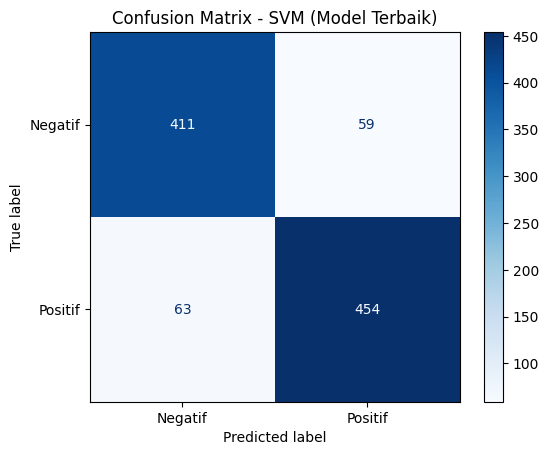

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

model_terbaik = SVC(kernel='linear', random_state=42)
model_terbaik.fit(X_train, y_train)
y_pred_terbaik = model_terbaik.predict(X_test)

cm = confusion_matrix(y_test, y_pred_terbaik, labels=['negatif', 'positif'])
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Negatif', 'Positif'])
disp.plot(cmap='Blues')
plt.title('Confusion Matrix - SVM (Model Terbaik)')
plt.show()

In [ ]:
print(df['label_rating'].value_counts())
print(df['label_rating'].value_counts(normalize=True) * 100)

label_rating
positif    2584
negatif    2350
Name: count, dtype: int64
label_rating
positif    52.371301
negatif    47.628699
Name: proportion, dtype: float64


## AKURASI

In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report
from sklearn.svm import SVC
import joblib

model_terbaik = SVC(kernel='linear', probability=True, random_state=42)
model_terbaik.fit(X_train, y_train)
y_pred_terbaik = model_terbaik.predict(X_test)

acc = accuracy_score(y_test, y_pred_terbaik)
prec = precision_score(y_test, y_pred_terbaik, average='weighted')
rec = recall_score(y_test, y_pred_terbaik, average='weighted')
f1 = f1_score(y_test, y_pred_terbaik, average='weighted')

print("\n=== Classification Report (SVM - Model Terbaik) ===")
print(classification_report(y_test, y_pred_terbaik))

joblib.dump(model_terbaik, 'svm_model.pkl')
print("\nModel SVM dengan probabilitas berhasil disimpan ke svm_model.pkl!")


=== Classification Report (SVM - Model Terbaik) ===
              precision    recall  f1-score   support

     negatif       0.87      0.87      0.87       470
     positif       0.88      0.88      0.88       517

    accuracy                           0.88       987
   macro avg       0.88      0.88      0.88       987
weighted avg       0.88      0.88      0.88       987


Model SVM dengan probabilitas berhasil disimpan ke svm_model.pkl!


### WordCloud

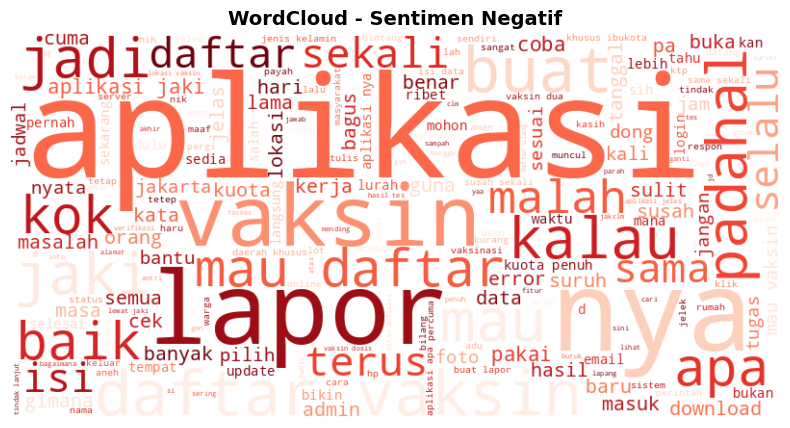

In [ ]:
from wordcloud import WordCloud
import matplotlib.pyplot as plt

teks_negatif = ' '.join(df[df['label'] == 'negatif']['teks_stemmed'])

wc_negatif = WordCloud(width=800, height=400, background_color='white',
                        colormap='Reds').generate(teks_negatif)

plt.figure(figsize=(10, 5))
plt.imshow(wc_negatif, interpolation='bilinear')
plt.title('WordCloud - Sentimen Negatif', fontsize=14, fontweight='bold')
plt.axis('off')
plt.show()

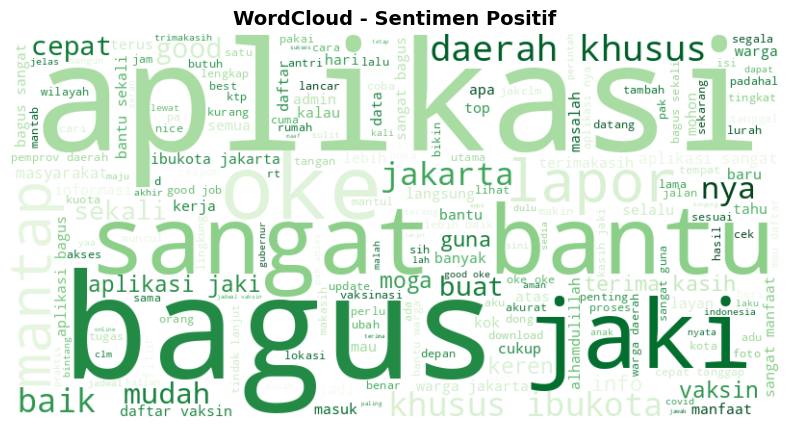

In [ ]:
teks_positif = ' '.join(df[df['label'] == 'positif']['teks_stemmed'])

wc_positif = WordCloud(width=800, height=400, background_color='white',
                        colormap='Greens').generate(teks_positif)

plt.figure(figsize=(10, 5))
plt.imshow(wc_positif, interpolation='bilinear')
plt.title('WordCloud - Sentimen Positif', fontsize=14, fontweight='bold')
plt.axis('off')
plt.show()

In [ ]:
from nltk.tokenize import word_tokenize

def preprocess_pipeline(text):
    text = clean_text_bert(text)
    text = normalize_text(text)
    tokens = word_tokenize(text)
    tokens = [t for t in tokens if t not in stopwords]
    text_stemmed = stemmer.stem(' '.join(tokens))
    return text_stemmed

def prediksi_sentimen(teks_input):
    try:
        teks_bersih = preprocess_pipeline(teks_input)
        vektor_teks = tfidf.transform([teks_bersih])

        prediksi = model_terbaik.predict(vektor_teks)[0]
        probabilitas = model_terbaik.predict_proba(vektor_teks)[0]
        kelas_model = model_terbaik.classes_

        teks_detail = f"Teks setelah preprocessing: {teks_bersih}\n\nProbabilitas:\n"
        for i, kelas in enumerate(kelas_model):
            teks_detail += f"- {kelas}: {probabilitas[i]:.2%}\n"

        hasil_akhir = "🤩 POSITIF" if prediksi.lower() == 'positif' else "😡 NEGATIF"

        return hasil_akhir, teks_detail

    except Exception as e:
        return f"Error: {str(e)}", "Gagal memproses data."

In [ ]:
while True:
    teks_input = input("Masukkan ulasan (atau ketik 'selesai' untuk berhenti): ")
    if teks_input.lower() == 'selesai':
        break
    hasil, detail = prediksi_sentimen(teks_input)
    print(f"\nPrediksi: {hasil}")
    print(detail)
    print("-" * 60)

Masukkan ulasan (atau ketik 'selesai' untuk berhenti): selesai


In [ ]:
import joblib

# Menyimpan model SVM (model_terbaik) dan TF-IDF
joblib.dump(model_terbaik, 'svm_model.pkl')
joblib.dump(tfidf, 'tfidf_vectorizer.pkl')

print("Model dan Vectorizer berhasil disimpan!")

Model dan Vectorizer berhasil disimpan!


In [ ]:
# Menyimpan dataframe ke dalam file CSV
df.to_csv('dataset_fixrev.csv', index=False)

print("Data preprocessing berhasil disimpan!")

Data preprocessing berhasil disimpan!
